# AI651 Assignment 2 — Question 2
## Name: Sadaf Aamer
## Roll Number: 25280007

In [ ]:
!pip -q install opencv-python-headless imageio tabulate

import os, time, json, math, random, copy
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

try:
    from google.colab import drive
    drive.mount('/content/drive')
    OUT = '/content/drive/MyDrive/AI651_A2_Q2'
except Exception:
    OUT = './AI651_A2_Q2'
for sub in ('ckpt', 'figs', 'gifs', 'tables', 'results'):
    os.makedirs(f'{OUT}/{sub}', exist_ok=True)

DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
torch.backends.cudnn.benchmark = True
EPOCHS, BATCH, LR = 30, 32, 1e-3
EVAL_BS = 100
TRAIN_IDX = range(0, 8000)
VAL_IDX = range(8000, 9000)
TEST_IDX = range(9000, 10000)
TABLES = {}

print('Device:', DEVICE, '|', torch.cuda.get_device_name(0) if DEVICE == 'cuda' else 'CPU only')
print('Saving to', OUT)

Mounted at /content/drive
Device: cuda | Tesla T4
Saving to /content/drive/MyDrive/AI651_A2_Q2


In [ ]:
from torchvision.datasets import MovingMNIST

ds = MovingMNIST(root='/content/data', split=None, download=True)
VIDEOS = ds.data if hasattr(ds, 'data') else torch.stack([ds[i] for i in range(len(ds))])
VIDEOS = VIDEOS.reshape(-1, 20, 1, 64, 64)
assert VIDEOS.shape == (10000, 20, 1, 64, 64) and VIDEOS.dtype == torch.uint8, VIDEOS.shape
VIDEOS_DEV = VIDEOS.to(DEVICE)
print(VIDEOS.shape, VIDEOS.dtype)

torch.Size([10000, 20, 1, 64, 64]) torch.uint8


## 1. Setup — transformations, windows, Table 1, Figure 1

In [ ]:
def mirror(x):
    return torch.flip(x, dims=(-1,))

def rotate(x, a=1):
    return torch.rot90(x, k=a % 4, dims=(-2, -1))

G = [(m, a) for m in (0, 1) for a in range(4)]
G_NAMES = ['R0', 'R1', 'R2', 'R3', 'MR0', 'MR1', 'MR2', 'MR3']

def apply_g(x, g):
    m, a = g
    y = rotate(x, a)
    return mirror(y) if m else y

def invert_g(x, g):
    m, a = g
    return apply_g(x, g) if m else rotate(x, -a)

def apply_g_batch(x, gidx):
    out = torch.empty_like(x)
    gidx = gidx.to(x.device)
    for gi in gidx.unique().tolist():
        sel = gidx == gi
        out[sel] = apply_g(x[sel], G[gi])
    return out

def frame_numbers(t, k=1):
    inp = [t + k * i for i in range(5)]
    tgt = [t + k * (5 + i) for i in range(5)]
    return inp, [f for f in tgt if f <= 20]

def get_window(video, t, k=1):
    inp, tgt = frame_numbers(t, k)
    return video[[f - 1 for f in inp]], video[[f - 1 for f in tgt]]

def allowed_starts(k, speed_aug):
    if not speed_aug:
        assert k == 1
        return list(range(1, 12))
    return [t for t in range(1, 21) if t + 4 * k <= 20 and t + 6 * k <= 20]

assert allowed_starts(1, True) == list(range(1, 15))
assert allowed_starts(2, True) == list(range(1, 9))
assert allowed_starts(3, True) == [1, 2]

_OFFS = torch.arange(10)
def gather_windows(videos_u8, vid, t, k):
    """Batched version of get_window used for training/evaluation.
    vid, t, k: (B,) long tensors. Returns X (B,5,1,64,64), Y (B,5,1,64,64) with missing
    target frames set to 0, and mask (B,5) marking which target frames exist."""
    dev = videos_u8.device
    vid, t, k = vid.to(dev), t.to(dev), k.to(dev)
    fr = (t - 1)[:, None] + k[:, None] * _OFFS.to(dev)[None]
    valid = fr <= 19
    clip = videos_u8[vid[:, None], fr.clamp(max=19)].float().div_(255)
    mask = valid[:, 5:]
    Y = clip[:, 5:] * mask[:, :, None, None, None]
    return clip[:, :5], Y, mask.float()

def make_windows(idx_range, k, t=1):
    vid = torch.arange(idx_range.start, idx_range.stop)
    n = len(vid)
    return gather_windows(VIDEOS_DEV, vid, torch.full((n,), t), torch.full((n,), k))

In [ ]:
torch.manual_seed(0); x = torch.rand(20, 1, 64, 64)
p = torch.zeros(20, 1, 64, 64); p[7, 0, 10, 20] = 1

def check(a, b):
    return f'{(a - b).abs().max().item():g} (torch.equal={torch.equal(a, b)})'

def bright(v):
    f, c, r, col = (v == 1).nonzero()[0].tolist()
    return (f, r, col)

frame_video = torch.arange(1, 21).float()[:, None, None, None].expand(20, 1, 64, 64)
def read_frames(k):
    X, Y = get_window(frame_video, 1, k)
    Xb, Yb, mb = gather_windows(frame_video.to(torch.uint8)[None], torch.tensor([0]), torch.tensor([1]), torch.tensor([k]))
    assert torch.equal(Xb[0] * 255, X) and torch.equal((Yb[0] * 255)[mb[0].bool()], Y)
    return ', '.join(str(int(f[0, 0, 0])) for f in X) + ' / ' + ', '.join(str(int(f[0, 0, 0])) for f in Y)

table1 = pd.DataFrame([
    ['(a) max|M(M(x)) − x|', '0', check(mirror(mirror(x)), x)],
    ['(b) max|R⁴(x) − x|', '0', check(rotate(rotate(rotate(rotate(x)))), x)],
    ['(c) max|MRM(x) − R⁻¹(x)|', '0', check(mirror(rotate(mirror(x))), rotate(x, -1))],
    ['(d) bright pixel of M(p)', '(7, 10, 43)', str(bright(mirror(p)))],
    ['(e) bright pixel of R(p)', '(7, 43, 10)', str(bright(rotate(p)))],
    ['(f) 1× input / target frames', '1–5 / 6–10', read_frames(1)],
    ['(g) 2× input / target frames', '1, 3, 5, 7, 9 / 11, 13, 15, 17, 19', read_frames(2)],
    ['(h) 3× input / target frames', '1, 4, 7, 10, 13 / 16, 19', read_frames(3)],
], columns=['Check', 'Expected', 'My Result'])
TABLES['Table 1'] = table1
display(table1)

,Check,Expected,My Result
0,(a) max|M(M(x)) − x|,0,0 (torch.equal=True)
1,(b) max|R⁴(x) − x|,0,0 (torch.equal=True)
2,(c) max|MRM(x) − R⁻¹(x)|,0,0 (torch.equal=True)
3,(d) bright pixel of M(p),"(7, 10, 43)","(7, 10, 43)"
4,(e) bright pixel of R(p),"(7, 43, 10)","(7, 43, 10)"
5,(f) 1× input / target frames,1–5 / 6–10,"1, 2, 3, 4, 5 / 6, 7, 8, 9, 10"
6,(g) 2× input / target frames,"1, 3, 5, 7, 9 / 11, 13, 15, 17, 19","1, 3, 5, 7, 9 / 11, 13, 15, 17, 19"
7,(h) 3× input / target frames,"1, 4, 7, 10, 13 / 16, 19","1, 4, 7, 10, 13 / 16, 19"


## Figure 1: optical flow statistics on the first 50 training videos

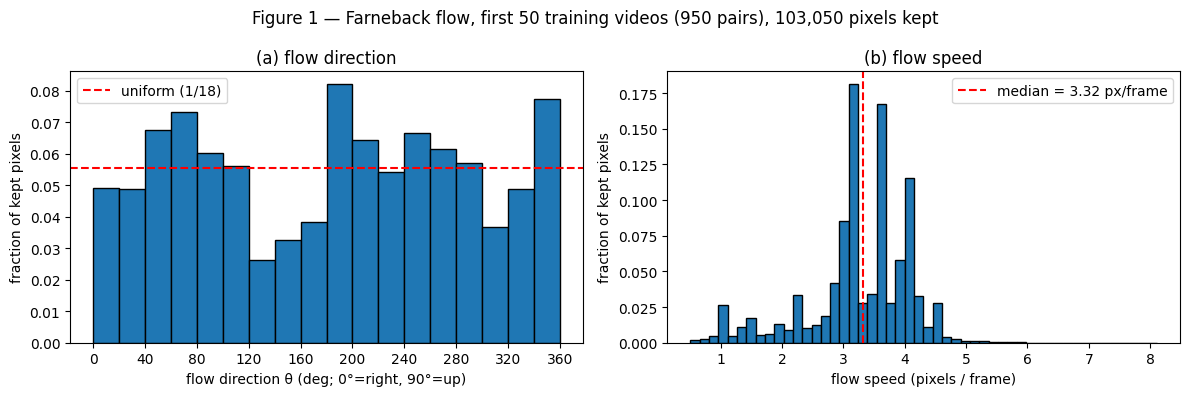

Median speed: 3.318 px/frame  ->  2x ≈ 6.64, 3x ≈ 9.95 px/frame;  pixels kept: 103,050


In [ ]:
import cv2
dx_all, dy_all = [], []
vids = VIDEOS[:50, :, 0].float() / 255
for v in vids:
    v8 = (v * 255).round().numpy().astype(np.uint8)
    for s in range(19):
        prev, nxt = v8[s], v8[s + 1]
        flow = cv2.calcOpticalFlowFarneback(prev, nxt, None, 0.5, 3, 15, 3, 5, 1.2, 0)
        dx, dy = flow[..., 0], flow[..., 1]
        keep = (v[s].numpy() > 0.2) & (v[s + 1].numpy() > 0.2) & (np.hypot(dx, dy) > 0.5)
        dx_all.append(dx[keep]); dy_all.append(dy[keep])
dx_all, dy_all = np.concatenate(dx_all), np.concatenate(dy_all)
theta = np.degrees(np.arctan2(-dy_all, dx_all)) % 360
speed = np.hypot(dx_all, dy_all)
n_kept, med = len(speed), np.median(speed)
w = np.full(n_kept, 1 / n_kept)

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].hist(theta, bins=np.arange(0, 361, 20), weights=w, edgecolor='k')
ax[0].axhline(1 / 18, color='r', ls='--', label='uniform (1/18)')
ax[0].set(xlabel='flow direction θ (deg; 0°=right, 90°=up)', ylabel='fraction of kept pixels',
          title='(a) flow direction', xticks=range(0, 361, 40)); ax[0].legend()
ax[1].hist(speed, bins=50, weights=w, edgecolor='k')
ax[1].axvline(med, color='r', ls='--', label=f'median = {med:.2f} px/frame')
ax[1].set(xlabel='flow speed (pixels / frame)', ylabel='fraction of kept pixels', title='(b) flow speed'); ax[1].legend()
fig.suptitle(f'Figure 1 — Farneback flow, first 50 training videos (950 pairs), {n_kept:,} pixels kept')
fig.tight_layout(); fig.savefig(f'{OUT}/figs/figure1_flow.png', dpi=150); plt.show()
print(f'Median speed: {med:.3f} px/frame  ->  2x ≈ {2*med:.2f}, 3x ≈ {3*med:.2f} px/frame;  pixels kept: {n_kept:,}')

**Q 2.1.** Based on Figure 1(a), would mirrored and rotated trajectories already be familiar to a model trained on this data? (Hint: how would the direction histogram change if every training video were mirrored? If every video were rotated by 90◦?)
From Figure 1(b), what is a typical speed, and what do 2× and 3× correspond to in pixels per frame? Optical flow
is unreliable where digits overlap; could that bias your histograms enough to change your
answer?  

**Answer:** Figure 1(a) shows that every direction appears in training. The 20° bins range from about 0.026 to 0.08, compared with 1/18 = 0.056 for a uniform distribution. Mirroring reflects the histogram about 90° (\(\theta \to 180^\circ-\theta\)), while a 90° rotation shifts it by 90° with wrap-around. Both transformations produce directions the model has already seen, with frequencies differing by at most about 3×. Thus, mirrored and rotated trajectories have familiar motion, and any failures are more likely due to changes in digit appearance. The unevenness is likely sampling noise, as 50 videos contain only about 100 trajectories, while wall bounces also encourage symmetry.  

Figure 1(b) shows a median speed of 3.32 px/frame, with most motion between 2.8 and 4.3 px/frame and almost none above 5. At 2× and 3×, speeds increase to approximately 6.6 and 10 px/frame, respectively, well beyond the training range. Faster playback therefore introduces unfamiliar motion, and at 3×, digits travel farther per frame than model A’s approximate one-step reach of 8 px.  

Overlapping digits can bias optical flow because Farneback blends their motions, making directions less accurate and speeds appear lower. This may explain the small peak around 1–2.5 px/frame, but is unlikely to change the overall conclusions. The direction histogram remains broadly representative, while underestimating speed would only widen the gap between training speeds and the 2× and 3× tests. Recomputing the histograms using only non-overlapping frame pairs with the no_overlap helper would help verify this.

**Q 2.2.** For each transformation, does it change the motion statistics, the digit appearance, or both?
Why does this make the three of them useful as a controlled experiment?\
**Answer:** Mirroring and rotation change how the digits look but leave their motion largely unchanged. For example, a mirrored 2, 3 or 7 may look very different from the training digits, while a rotated 4 appears sideways. Digits such as 0 and 8, however, remain relatively similar because of their symmetry. The motion itself is still familiar: speed stays the same, and Figure 1(a) shows that all reflected and rotated directions already appear in training, with frequencies differing by at most about 3×. Since the frame is square, wall bounces also remain physically valid after either transformation.  

Speed-up has the opposite effect: the digits look the same, but move faster. Taking every second or third frame increases their speed from about 3.3 px/frame to 6.6 or 10 px/frame, well beyond the training range. Wall bounces also occur over fewer observed frames.  

Together, these tests help separate the effects of appearance and motion. If model A fails on mirrored or rotated videos, the problem is likely the changed appearance; if it fails on speed-up, unfamiliar motion is the more likely cause. The two appearance tests also reveal different sensitivities: mirroring reverses a digit's handedness, while rotation changes its orientation. Finally, no new data or labels are needed: the correct outputs for mirroring and rotation can be obtained by transforming the original ground truth \(T(Y)\), while speed-up uses actual later frames from the same video.

## 2. Baseline: ConvLSTM (model A) — and the model class reused for model D

In [ ]:
class ConvLSTMCell(nn.Module):
    def __init__(self, cin, hidden, k=3, dilation=1):
        super().__init__()
        self.hidden = hidden
        self.conv = nn.Conv2d(cin + hidden, 4 * hidden, k, padding=dilation * (k - 1) // 2,
                              dilation=dilation, bias=True)

    def forward(self, u, state):
        h, c = state
        i, f, o, g = self.conv(torch.cat([u, h], dim=1)).chunk(4, dim=1)
        c = torch.sigmoid(f) * c + torch.sigmoid(i) * torch.tanh(g)
        h = torch.sigmoid(o) * torch.tanh(c)
        return h, c


class ConvLSTMForecaster(nn.Module):
    """patch: pixel_unshuffle factor; kernels / dilations: one entry per ConvLSTM layer."""
    def __init__(self, patch=4, hidden=64, kernels=(3, 3), dilations=(1, 1)):
        super().__init__()
        self.patch, self.hidden = patch, hidden
        cin = patch * patch
        self.cells = nn.ModuleList([
            ConvLSTMCell(cin if l == 0 else hidden, hidden, k, d)
            for l, (k, d) in enumerate(zip(kernels, dilations))])
        self.out = nn.Conv2d(hidden, cin, 1, bias=True)

    def init_states(self, B, device, dtype=torch.float32):
        s = 64 // self.patch
        z = lambda: torch.zeros(B, self.hidden, s, s, device=device, dtype=dtype)
        return [(z(), z()) for _ in self.cells]

    def step(self, u, states):
        z = F.pixel_unshuffle(u, self.patch)
        new = []
        for cell, st in zip(self.cells, states):
            h, c = cell(z, st)
            new.append((h, c)); z = h
        return torch.sigmoid(F.pixel_shuffle(self.out(z), self.patch)), new

    def forward(self, X):
        states = self.init_states(X.shape[0], X.device, X.dtype)
        preds, pred = [], None
        for tau in range(1, 10):
            u = X[:, tau - 1] if tau <= 5 else pred
            pred, states = self.step(u, states)
            if tau >= 5:
                preds.append(pred)
        return torch.stack(preds, dim=1)


def n_params(m):
    return sum(p.numel() for p in m.parameters() if p.requires_grad)

CFG_A = dict(patch=4, hidden=64, kernels=(3, 3), dilations=(1, 1))
assert n_params(ConvLSTMForecaster(**CFG_A)) == 480_784, n_params(ConvLSTMForecaster(**CFG_A))
print('Model A trainable parameters:', n_params(ConvLSTMForecaster(**CFG_A)))


def empirical_reach(cfg, seed=0):
    torch.manual_seed(seed)
    m = ConvLSTMForecaster(**cfg).double()
    p, s = m.patch, 64 // m.patch
    u = torch.rand(1, 1, 64, 64, dtype=torch.double, requires_grad=True)
    states = [(torch.randn(1, m.hidden, s, s, dtype=torch.double, requires_grad=True),
               torch.randn(1, m.hidden, s, s, dtype=torch.double, requires_grad=True)) for _ in m.cells]
    pred, _ = m.step(u, states)
    oy = ox = 32
    leaves = [u] + [t for st in states for t in st]
    grads = torch.autograd.grad(pred[0, 0, oy, ox], leaves)
    oc = (oy // p, ox // p)
    report = {}
    names = ['u_tau'] + [f'{n}{l+1}_(tau-1)' for l in range(len(m.cells)) for n in ('h', 'c')]
    for name, g in zip(names, grads):
        g = g[0].abs()
        if name == 'u_tau':
            g = F.pixel_unshuffle(g[None], p)[0]
        nz = (g.sum(0) > 0).nonzero()
        d = max(max(abs(r - oc[0]), abs(c - oc[1])) for r, c in nz.tolist()) if len(nz) else 0
        report[name] = d * p
    return report, max(report.values())

print('Model A one-step reach check (pixels):', empirical_reach(CFG_A))

Model A trainable parameters: 480784
Model A one-step reach check (pixels): ({'u_tau': 8, 'h1_(tau-1)': 8, 'c1_(tau-1)': 4, 'h2_(tau-1)': 4, 'c2_(tau-1)': 0}, 8)


## Training

In [ ]:

def _sync():
    if DEVICE == 'cuda':
        torch.cuda.synchronize()

def load_ckpt(path):
    ck = torch.load(path, map_location=DEVICE, weights_only=False)
    m = ConvLSTMForecaster(**ck['cfg']).to(DEVICE)
    m.load_state_dict(ck['state']); m.eval()
    return m, ck['info']

def train(name, cfg, seed, speed_aug=False, sym_aug=False, epochs=None, train_idx=None):
    epochs = epochs or EPOCHS
    train_idx = train_idx or TRAIN_IDX
    final = f'{OUT}/ckpt/{name}_s{seed}.pt'
    partial = f'{OUT}/ckpt/{name}_s{seed}_partial.pt'
    if os.path.exists(final):
        print(f'[{name} s{seed}] loaded finished checkpoint')
        return load_ckpt(final)

    torch.manual_seed(seed); np.random.seed(seed); random.seed(seed)
    model = ConvLSTMForecaster(**cfg).to(DEVICE)
    opt = torch.optim.Adam(model.parameters(), lr=LR)
    gen = torch.Generator().manual_seed(seed)
    info = dict(name=name, seed=seed, cfg=cfg, speed_aug=speed_aug, sym_aug=sym_aug,
                params=n_params(model), epoch_times=[], losses=[],
                hardware=torch.cuda.get_device_name(0) if DEVICE == 'cuda' else 'CPU')
    start = 0
    if os.path.exists(partial):
        ck = torch.load(partial, map_location=DEVICE, weights_only=False)
        model.load_state_dict(ck['state']); opt.load_state_dict(ck['opt'])
        gen.set_state(ck['gen']); torch.set_rng_state(ck['torch_rng'])
        if DEVICE == 'cuda' and ck.get('cuda_rng') is not None:
            torch.cuda.set_rng_state(ck['cuda_rng'])
        info, start = ck['info'], ck['epoch']
        print(f'[{name} s{seed}] resuming from epoch {start}')

    ids = torch.arange(train_idx.start, train_idx.stop)
    speeds = (1, 2, 3) if speed_aug else (1,)
    starts = {k: torch.tensor(allowed_starts(k, speed_aug)) for k in speeds}
    for ep in range(start, epochs):
        model.train(); _sync(); t0 = time.time()
        perm = ids[torch.randperm(len(ids), generator=gen)]
        n = len(perm)
        k = torch.randint(1, 4, (n,), generator=gen) if speed_aug else torch.ones(n, dtype=torch.long)
        t = torch.empty(n, dtype=torch.long)
        for kk, st in starts.items():
            sel = k == kk
            t[sel] = st[torch.randint(len(st), (int(sel.sum()),), generator=gen)]
        g = torch.randint(0, 8, (n,), generator=gen) if sym_aug else None
        total = torch.zeros((), device=DEVICE)
        for b in range(0, n, BATCH):
            sl = slice(b, b + BATCH)
            X, Y, mask = gather_windows(VIDEOS_DEV, perm[sl], t[sl], k[sl])
            if sym_aug:
                X, Y = apply_g_batch(X, g[sl]), apply_g_batch(Y, g[sl])
            pred = model(X)
            se = ((pred - Y) ** 2).mean(dim=(2, 3, 4))
            loss = ((se * mask).sum(1) / mask.sum(1)).mean()
            opt.zero_grad(set_to_none=True)
            loss.backward()
            opt.step()
            total += loss.detach() * X.shape[0]
        _sync()
        info['epoch_times'].append(time.time() - t0)
        info['losses'].append(total.item() / n)
        print(f'[{name} s{seed}] epoch {ep+1:2d}/{epochs}  loss {info["losses"][-1]:.5f}  {info["epoch_times"][-1]:.1f}s')
        torch.save(dict(state=model.state_dict(), opt=opt.state_dict(), gen=gen.get_state(),
                        torch_rng=torch.get_rng_state(),
                        cuda_rng=torch.cuda.get_rng_state() if DEVICE == 'cuda' else None,
                        info=info, epoch=ep + 1), partial)
    info['train_time_per_epoch'] = float(np.mean(info['epoch_times']))
    model.eval()
    torch.save(dict(state=model.state_dict(), cfg=cfg, info=info), final)
    if os.path.exists(partial):
        os.remove(partial)
    return model, info

In [ ]:
WIN_TEST = {k: make_windows(TEST_IDX, k) for k in (1, 2, 3)}     # t = 1 test windows
assert WIN_TEST[2][2].all(), '2x with t=1 should have all five targets'
X1, Y1, _ = WIN_TEST[1]

def blank(X):
    return torch.zeros_like(X)

def copy_last(X):
    return X[:, -1:].expand_as(X).clone()

class Symmetrised(nn.Module):
    """f_bar(X) = 1/8 sum_g g^-1( f( g(X) ) )"""
    def __init__(self, f):
        super().__init__()
        self.f = f
    def forward(self, X):
        return sum(invert_g(self.f(apply_g(X, g)), g) for g in G) / len(G)

@torch.no_grad()
def run(f, X, bs=EVAL_BS):
    if isinstance(f, nn.Module):
        f.eval()
    return torch.cat([f(X[i:i + bs]) for i in range(0, len(X), bs)])

def per_video_mse(P, Y):
    return ((P - Y) ** 2).mean(dim=(2, 3, 4))

def evaluate(f, win=None):
    win = win or WIN_TEST
    X, Y, _ = win[1]
    P = run(f, X)
    m = per_video_mse(P, Y)
    res = {f'MSE{h+1}': m[:, h].mean().item() for h in range(5)}
    res['E5_1x'] = m.mean().item()
    res['E2_1x'] = m[:, :2].mean().item()
    for T, tn in ((mirror, 'M'), (rotate, 'R')):
        PT = run(f, T(X))
        c = per_video_mse(PT, T(P)).mean(1)
        e = per_video_mse(PT, T(Y)).mean(1)
        res['C' + tn], res['E' + tn] = c.mean().item(), e.mean().item()
        res['C' + tn + '_pv'], res['E' + tn + '_pv'] = c.cpu().numpy(), e.cpu().numpy()
    for k in (2, 3):
        Xk, Yk, mk = win[k]
        mm = per_video_mse(run(f, Xk), Yk)
        res[f'E2_{k}x'] = mm[:, :2].mean().item()
        if k == 2:
            res['E5_2x'] = mm.mean().item()
    return res

@torch.no_grad()
def inference_time(f, bs=32):
    """Wall-clock time to predict the 1,000 original (1x, t=1) test videos at batch size 32.
    Test batches are already on the device. One warm-up batch is excluded (CUDA initialisation)."""
    if isinstance(f, nn.Module):
        f.eval()
    batches = [X1[i:i + bs] for i in range(0, len(X1), bs)]
    f(batches[0]); _sync()
    t0 = time.time()
    for xb in batches:
        f(xb)
    _sync()
    return time.time() - t0

RESULTS = {}

def get_results(name, seed, f, cache=True):
    key = (name, seed)
    path = f'{OUT}/results/{name}_s{seed}.pt'
    if key not in RESULTS and cache and os.path.exists(path):
        RESULTS[key] = torch.load(path, weights_only=False)
    if key not in RESULTS:
        r = evaluate(f)
        r['infer_time'] = inference_time(f)
        RESULTS[key] = r
        torch.save(r, path)
    return RESULTS[key]

def fmt(v):
    if v is None or (isinstance(v, float) and math.isnan(v)):
        return '—'
    if isinstance(v, (int, np.integer)):
        return f'{v:,}'
    if v == 0:
        return '0'
    return f'{v:.2e}' if abs(v) < 1e-3 else f'{v:.3g}'

def entry(vals):
    if len(vals) == 1:
        return fmt(vals[0])
    return f'{fmt(float(np.mean(vals)))} ({fmt(vals[0])}, {fmt(vals[1])})'

def make_table(rows, cols, labels):
    """rows: list of (row label, [result dicts], extra dict{col: str}); cols: result keys."""
    data = []
    for label, rs, extra in rows:
        line = {'Model': label}
        for c, lab in zip(cols, labels):
            if c in (extra or {}):
                line[lab] = extra[c]
            else:
                line[lab] = entry([r[c] for r in rs])
        data.append(line)
    return pd.DataFrame(data)

R_BLANK = get_results('Blank', None, blank)
R_COPY = get_results('CopyLast', None, copy_last)
HARDWARE = torch.cuda.get_device_name(0) if DEVICE == 'cuda' else 'CPU'
print('Hardware:', HARDWARE)

Hardware: Tesla T4


In [ ]:
# plotting helpers
from scipy import ndimage
from PIL import Image, ImageDraw

def to_np(v):
    return v.detach().float().cpu().squeeze().numpy()

def n_blobs(frame, thr=0.2, min_size=20):
    lab, n = ndimage.label(to_np(frame) > thr)
    if n == 0:
        return 0
    sizes = ndimage.sum(np.ones_like(lab), lab, range(1, n + 1))
    return int((np.asarray(sizes) >= min_size).sum())

def has_overlap(frames):
    return any(n_blobs(f) < 2 for f in frames)

def no_overlap(frames):
    return all(n_blobs(f) == 2 for f in frames)

def seq_grid(rows, row_labels, title, path, col_titles=None, split=5):
    """rows: list of lists of frames (each (1,64,64) or (64,64)); a red line after column `split`."""
    nr, nc = len(rows), max(len(r) for r in rows)
    fig, axes = plt.subplots(nr, nc, figsize=(1.25 * nc, 1.3 * nr + 0.6), squeeze=False)
    for i, r in enumerate(rows):
        for j in range(nc):
            ax = axes[i, j]; ax.set_xticks([]); ax.set_yticks([])
            if j < len(r):
                ax.imshow(to_np(r[j]), cmap='gray', vmin=0, vmax=1)
            else:
                ax.axis('off')
            if split and j == split:
                for s in ax.spines.values():
                    s.set_edgecolor('red'); s.set_linewidth(1.5)
        axes[i, 0].set_ylabel(row_labels[i], rotation=0, ha='right', va='center', fontsize=8)
    if col_titles:
        for j, t in enumerate(col_titles):
            axes[0, j].set_title(t, fontsize=8)
    fig.suptitle(title, fontsize=10)
    fig.tight_layout(); fig.savefig(path, dpi=130); plt.show()

def save_gif(rows, row_labels, path, scale=2):
    """Each GIF frame h = 1..5 shows the four rows: [last input frame | frame at horizon h]."""
    frames = []
    for h in range(5):
        pad, lab_w = 4, 150
        W = lab_w + 2 * 64 * scale + 3 * pad
        Hh = len(rows) * (64 * scale + pad) + 22
        canvas = Image.new('L', (W, Hh), 40)
        d = ImageDraw.Draw(canvas)
        d.text((lab_w, 4), f'last input  |  horizon h={h+1}', fill=255)
        for i, (r, lab) in enumerate(zip(rows, row_labels)):
            y0 = 22 + i * (64 * scale + pad)
            d.text((4, y0 + 20), lab, fill=255)
            for j, img in enumerate((r[4], r[5 + h])):
                a = (np.clip(to_np(img), 0, 1) * 255).astype(np.uint8)
                im = Image.fromarray(a).resize((64 * scale, 64 * scale), Image.NEAREST)
                canvas.paste(im, (lab_w + pad + j * (64 * scale + pad), y0))
        frames.append(canvas)
    frames[0].save(path, save_all=True, append_images=frames[1:], duration=700, loop=0)

def consistency_rows(f, vid_pos, T):
    """Four rows of Figure 3 for test video at position vid_pos (0..999)."""
    X, Y = X1[vid_pos:vid_pos + 1], Y1[vid_pos:vid_pos + 1]
    with torch.no_grad():
        fX, fTX = f(X), f(T(X))
    TX, TY, TfX = T(X), T(Y), T(fX)
    cat = lambda a, b: list(torch.cat([a[0], b[0]]))
    return [cat(X, fX), cat(TX, TY), cat(TX, fTX), cat(TX, TfX)]

def consistency_figure(f, picks, fig_name, model_label):
    """picks: list of (test position, 'M' or 'R'). Saves PNG + one GIF per panel; returns GIF paths."""
    gif_paths = []
    for pos, tn in picks:
        T = mirror if tn == 'M' else rotate
        rows = consistency_rows(f, pos, T)
        labels = ['X | f(X)', f'{tn}(X) | {tn}(Y)', f'{tn}(X) | f({tn}(X))', f'{tn}(X) | {tn}(f(X))']
        vid = TEST_IDX.start + pos
        seq_grid(rows, labels, f'{fig_name} — {model_label}, T={tn}, test video {vid}',
                 f'{OUT}/figs/{fig_name}_{tn}_video{vid}.png',
                 col_titles=[f'in {i}' for i in range(1, 6)] + [f'h={h}' for h in range(1, 6)])
        gp = f'{OUT}/gifs/{fig_name}_{tn}_video{vid}.gif'
        save_gif(rows, labels, gp); gif_paths.append(gp)
    print('GIFs:', *gif_paths, sep='\n  ')
    return gif_paths

def speed_figure(f, pos, fig_name, model_label):
    rows, labels = [], []
    for k in (1, 2, 3):
        X, Y, _ = WIN_TEST[k]
        with torch.no_grad():
            P = f(X[pos:pos + 1])
        rows.append(list(X[pos]) + list(P[0, :2]) + list(Y[pos, :2]))
        labels.append(f'{k}×')
    in_titles = ['in 1', 'in 2', 'in 3', 'in 4', 'in 5', 'pred h=1', 'pred h=2', 'true h=1', 'true h=2']
    seq_grid(rows, labels, f'{fig_name} — {model_label}, test video {TEST_IDX.start + pos} at 1×, 2×, 3× (t=1)',
             f'{OUT}/figs/{fig_name}_video{TEST_IDX.start + pos}.png', col_titles=in_titles, split=5)

### Train model A (seeds 0 and 1)

In [ ]:
MODELS = {}
for s in (0, 1):
    MODELS[('A', s)] = train('A', CFG_A, s)
for s in (0, 1):
    m, info = MODELS[('A', s)]
    print(f'A seed {s}: params {info["params"]:,}, {info["train_time_per_epoch"]:.1f} s/epoch, final loss {info["losses"][-1]:.5f}')

[A s0] epoch  1/30  loss 0.04611  13.2s
[A s0] epoch  2/30  loss 0.03967  10.3s
[A s0] epoch  3/30  loss 0.03867  10.3s
[A s0] epoch  4/30  loss 0.03713  10.6s
[A s0] epoch  5/30  loss 0.03526  10.9s
[A s0] epoch  6/30  loss 0.03359  11.4s
[A s0] epoch  7/30  loss 0.03225  11.2s
[A s0] epoch  8/30  loss 0.03131  10.8s
[A s0] epoch  9/30  loss 0.03040  10.7s
[A s0] epoch 10/30  loss 0.02975  10.6s
[A s0] epoch 11/30  loss 0.02930  10.6s
[A s0] epoch 12/30  loss 0.02876  10.7s
[A s0] epoch 13/30  loss 0.02838  10.8s
[A s0] epoch 14/30  loss 0.02803  10.8s
[A s0] epoch 15/30  loss 0.02756  10.9s
[A s0] epoch 16/30  loss 0.02717  10.8s
[A s0] epoch 17/30  loss 0.02686  10.8s
[A s0] epoch 18/30  loss 0.02638  10.8s
[A s0] epoch 19/30  loss 0.02614  10.7s
[A s0] epoch 20/30  loss 0.02568  10.8s
[A s0] epoch 21/30  loss 0.02531  10.8s
[A s0] epoch 22/30  loss 0.02501  10.8s
[A s0] epoch 23/30  loss 0.02445  10.8s
[A s0] epoch 24/30  loss 0.02424  10.8s
[A s0] epoch 25/30  loss 0.02386  10.8s


,Model,MSE₁,MSE₂,MSE₃,MSE₄,MSE₅,E⁽⁵⁾,Params
0,A (ConvLSTM),"0.0172 (0.0175, 0.017)","0.0205 (0.0208, 0.0203)","0.0228 (0.0231, 0.0225)","0.0245 (0.0248, 0.0242)","0.0262 (0.0264, 0.0259)","0.0222 (0.0225, 0.022)","480,784"
1,Blank,0.0426,0.0426,0.0426,0.0425,0.0425,0.0426,0
2,Copy-last,0.0492,0.0604,0.0669,0.0708,0.0732,0.0641,0


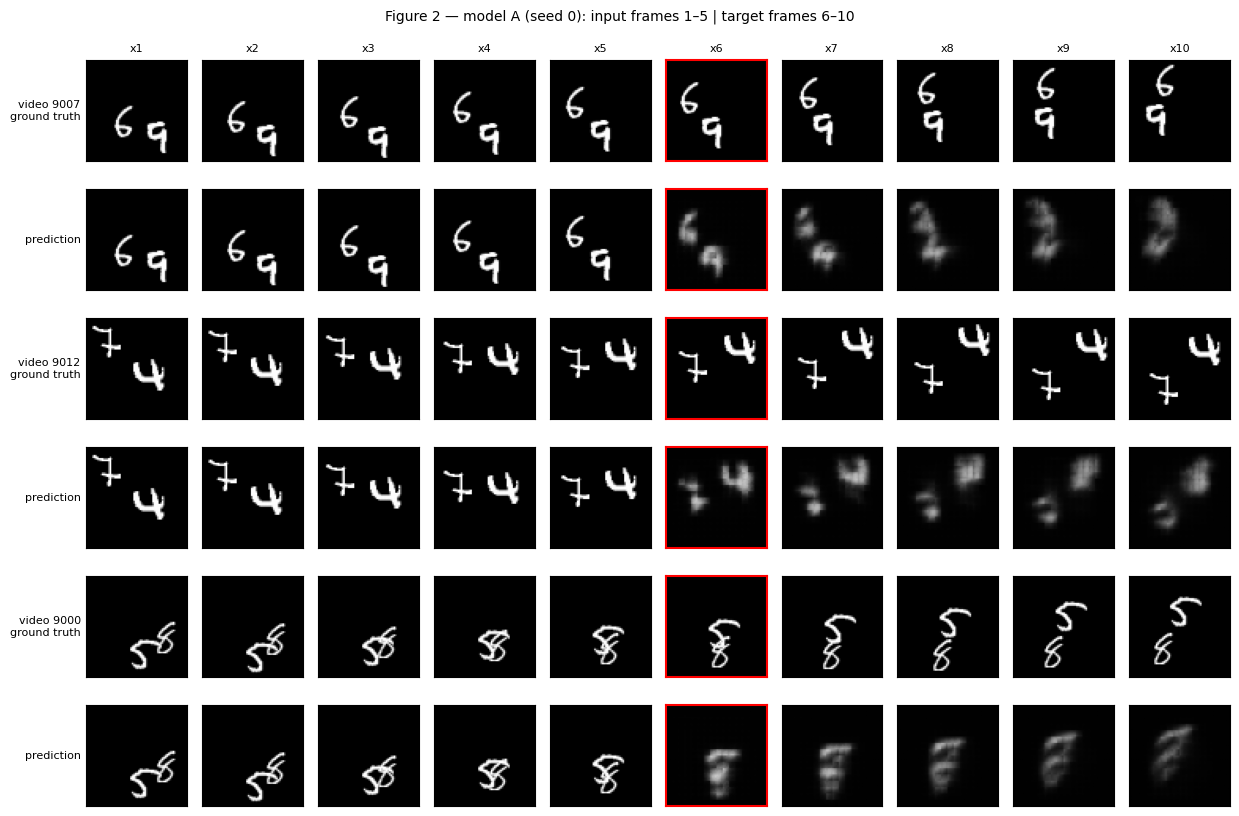

Figure 2 test videos: [9007, 9012, 9000] (last one chosen as overlapping)


In [ ]:
# Table 2 and Figure 2
RA = [get_results('A', s, MODELS[('A', s)][0]) for s in (0, 1)]
cols = ['MSE1', 'MSE2', 'MSE3', 'MSE4', 'MSE5', 'E5_1x', 'params']
labs = ['MSE₁', 'MSE₂', 'MSE₃', 'MSE₄', 'MSE₅', 'E⁽⁵⁾', 'Params']
table2 = make_table([('A (ConvLSTM)', RA, {'params': fmt(MODELS[('A', 0)][1]['params'])}),
                     ('Blank', [R_BLANK], {'params': '0'}),
                     ('Copy-last', [R_COPY], {'params': '0'})], cols, labs)
TABLES['Table 2'] = table2
display(table2)

FIG2_POS = None
if FIG2_POS is None:
    over = [i for i in range(len(X1)) if has_overlap(list(Y1[i]))]
    clean = [i for i in range(len(X1)) if no_overlap(list(X1[i]) + list(Y1[i]))]
    FIG2_POS = clean[:2] + over[:1]
mA = MODELS[('A', 0)][0]
with torch.no_grad():
    PA = mA(X1[FIG2_POS])
rows, labels = [], []
for j, pos in enumerate(FIG2_POS):
    rows += [list(X1[pos]) + list(Y1[pos]), list(X1[pos]) + list(PA[j])]
    labels += [f'video {TEST_IDX.start+pos}\nground truth', 'prediction']
seq_grid(rows, labels, 'Figure 2 — model A (seed 0): input frames 1–5 | target frames 6–10',
         f'{OUT}/figs/figure2.png', col_titles=[f'x{i}' for i in range(1, 11)])
print('Figure 2 test videos:', [TEST_IDX.start + p for p in FIG2_POS], '(last one chosen as overlapping)')

**Q2.3.** Estimate model A’s reach in original pixels per time step, using the conventions above. Walk
through your reasoning from the patch size, kernel sizes, number of layers and the recurrence.
There is no formula to look up for this.  

**Answer:** Model A first uses pixel_unshuffle to convert each \\(64\times64\\) frame into a \\(16\times16\\) grid with 16 channels. Each grid cell represents 4 original pixels. The folding, final pixel_shuffle, and 1×1 output convolution only mix channels, so they do not move information spatially.  

The only operations that move information are the 3×3 convolutions in the two stacked ConvLSTM layers. Each convolution can pass information one cell in any direction, equivalent to 4 pixels. Since the layers are stacked, information from the new frame \\(u\_\tau\\) or the previous hidden state \\(h^{(1)}\_{\tau-1}\\) can travel through both layers, reaching 8 pixels per time step. The second layer's previous hidden state \\(h^{(2)}\_{\tau-1}\\) passes through only one convolution, reaching 4 pixels. The elementwise gate activations and cell-state updates add no spatial movement.

Recurrence provides memory across time, allowing information to move further over multiple steps. However, the network must connect a digit's previous and current positions within its per-step reach to track it effectively.

A gradient-based check confirms these distances and gives 480,784 trainable parameters. Compared with Figure 1, the typical speed of 3.3 px/frame is comfortably within the 8-pixel reach, while 2× speed (6.6 px/frame) approaches the limit. At 3× speed (about 10 px/frame), digits can move too far for the network to connect their positions in a single step.

**Q2.4.** Using Table 2 and Figure 2, how does model A compare with the two reference predictors,
and how does its error grow over the five forecast horizons? What happens to its predictions
when digits overlap?


**Answer:** Model A clearly outperforms both baselines at every horizon. Its E^(5) is 0.0222, roughly half of Blank’s 0.0426 and a third of Copy-last’s 0.0641. Both seeds give nearly identical results, suggesting the performance is stable. Interestingly, Copy-last performs worse than Blank even at \(h=1\) (0.0492 vs. 0.0426). Since digits move about 3.3 pixels per frame, copying the previous frame leaves both missing pixels where the digit has moved and incorrect bright pixels where it used to be. Blank only incurs the first error.

Model A’s error increases from 0.0172 at \(h=1\) to 0.0262 at \(h=5\), but the increases become smaller over time. Figure 2 shows why: predictions become blurry almost immediately and fade into grey smudges by \(x8\)–\(x10\). From step 6 onwards, the model feeds its own predictions back as input, causing the blur to accumulate. Under MSE, spreading brightness across possible positions can be less costly than predicting a sharp digit in the wrong place. As a result, the predictions gradually approach Blank’s performance. Low MSE at longer horizons does not necessarily mean accurate predictions; the model increasingly captures the approximate location of the digits rather than their shapes.

Video 9012 shows that Model A can roughly track motion when digits remain separate. It predicts the 4 moving up and right and the 7 moving down and left, although their shapes quickly dissolve.

Overlap causes greater problems. In video 9000, the 5 and 8 overlap and then separate in the ground truth, but Model A produces a single fading smear instead. In video 9007, the 6 and 9 merge into one blob and remain merged. When digits overlap, the model struggles to distinguish their strokes and individual motion. Under MSE, spreading brightness across several possible positions is a safer prediction than committing to uncertain locations, resulting in the merged, blurry outputs.

**Q2.5.** Before you run any experiment in Testing the Baseline, write down your predictions: will
model A pass the mirror test? The rotation test? At what speed should it break down, given
your reach estimate and Figure 1? Include this answer in your report exactly as you
first wrote it, even if it turns out to be wrong.

**Answer:**  

**Mirror and rotation:** I expect Model A to handle both reasonably well because the transformed motion directions already appear in training. However, mirrored and rotated digits look different, and the architecture does not enforce mirror or rotation symmetry, so \(C_M\) and \(C_R\) should be nonzero. Since Figure 2 shows that predictions quickly lose their digit shapes and become blurry blobs, I expect \(E_M\) and \(E_R\) to remain close to the original (E^(5) = 0.022), within roughly 10%. Mirror and rotation should perform similarly.

**Speed-up:** I expect performance to deteriorate more noticeably because the network’s reach is 8 pixels per step, compared with a typical training speed of 3.3 px/frame.
* At 2× (6.6 px/frame): Motion remains within the network’s reach but is faster than most training examples. I expect (E^(2)) to increase while remaining below Copy-last’s error.
* At 3× (about 10 px/frame): Digits can move beyond the network’s reach between frames. I expect substantial failure, with (E^(2)) approaching or exceeding Blank’s error and predictions becoming blurred or lagging behind the true positions.

## 3. Testing the baseline

,Model,E⁽⁵⁾,C_M,E_M,C_R,E_R
0,A,"0.0222 (0.0225, 0.022)","0.00163 (0.00155, 0.00171)","0.0228 (0.0231, 0.0226)","0.00288 (0.00254, 0.00321)","0.024 (0.024, 0.0239)"
1,Blank,0.0426,0,0.0426,0,0.0426
2,Copy-last,0.0641,0,0.0641,0,0.0641


Figure 3 videos: [(9269, 'M'), (9499, 'M'), (9031, 'R'), (9150, 'R')]


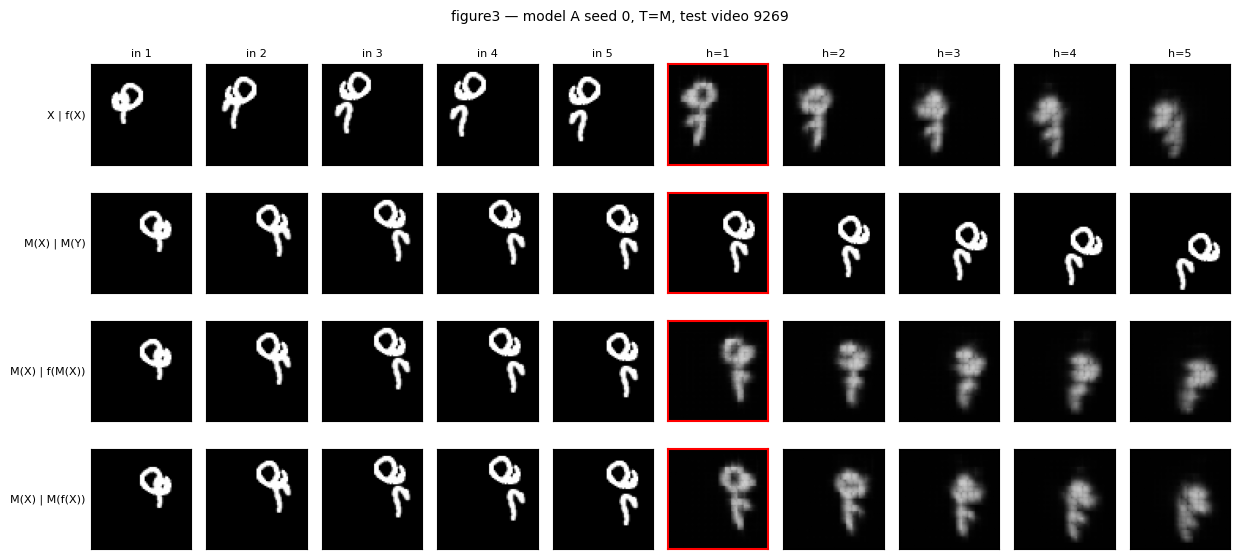

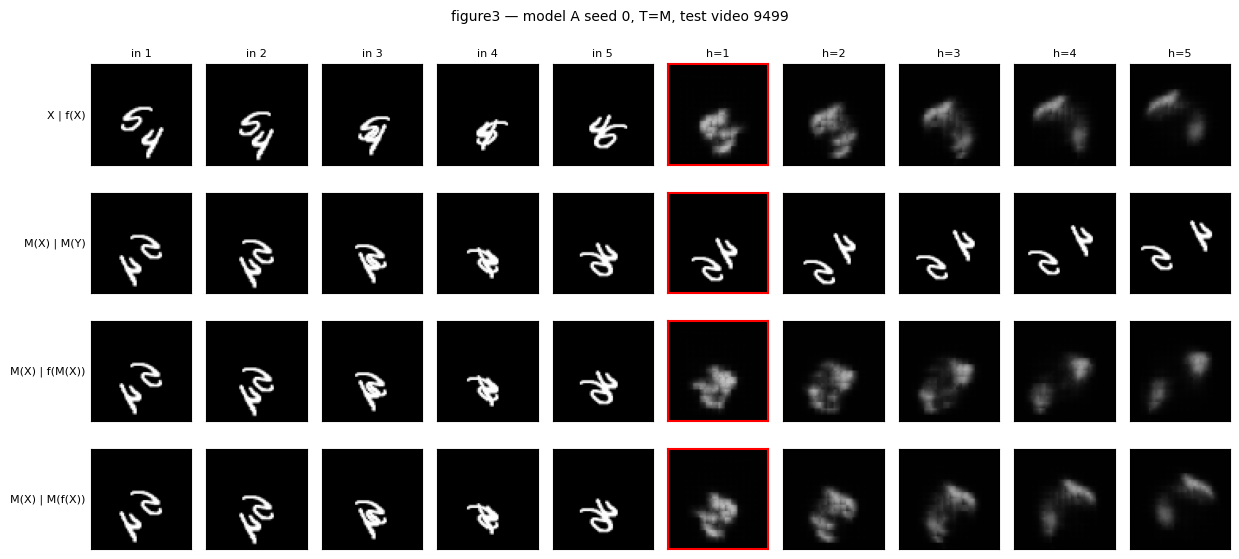

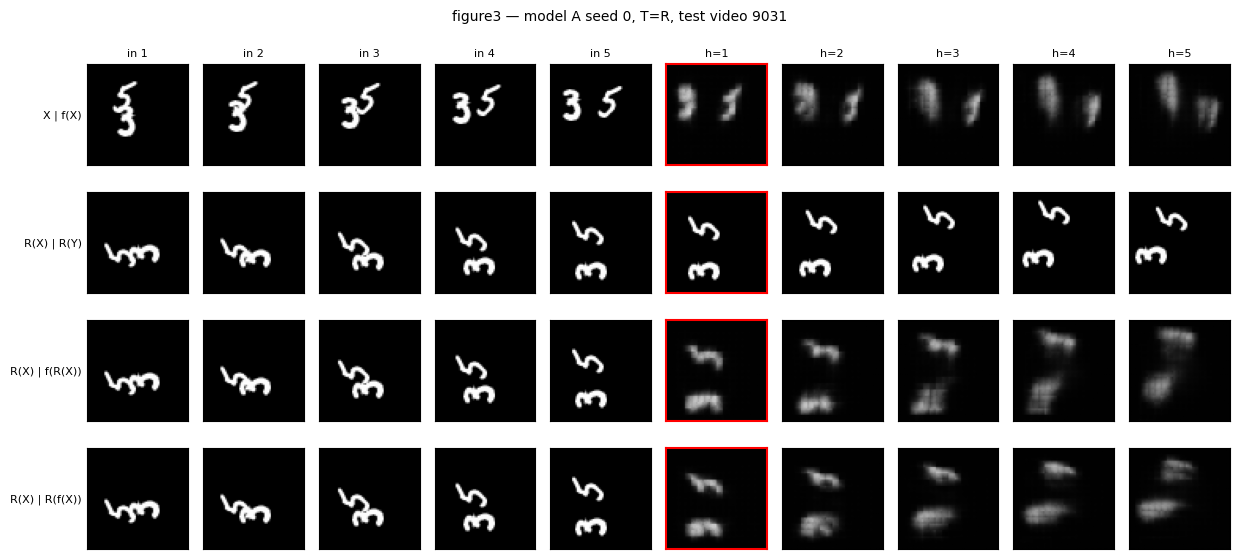

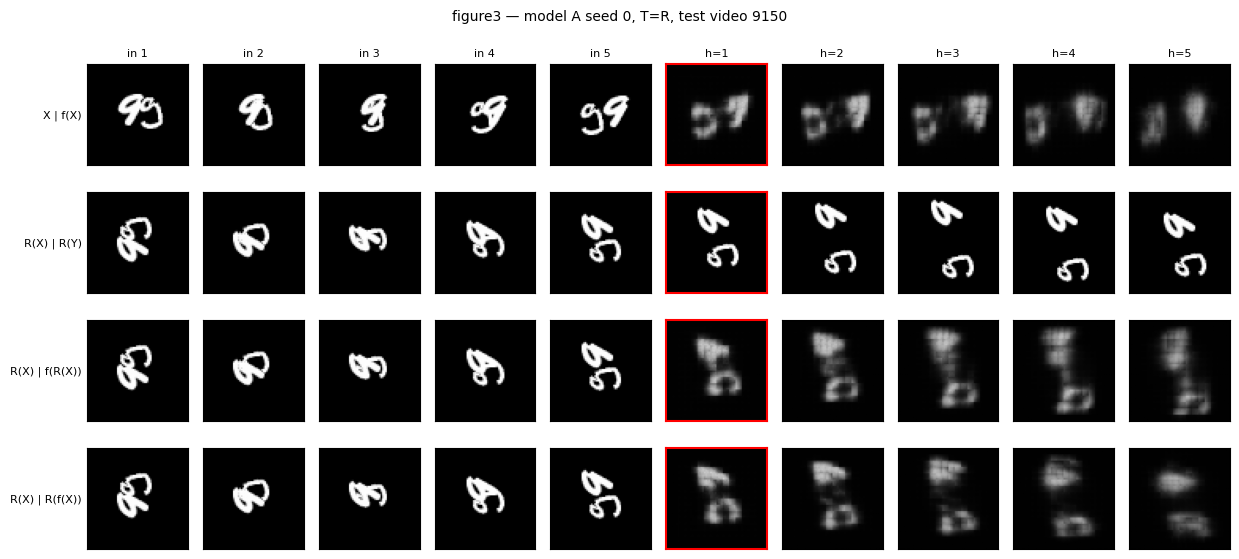

GIFs:
  ./AI651_A2_Q2/gifs/figure3_M_video9269.gif
  ./AI651_A2_Q2/gifs/figure3_M_video9499.gif
  ./AI651_A2_Q2/gifs/figure3_R_video9031.gif
  ./AI651_A2_Q2/gifs/figure3_R_video9150.gif


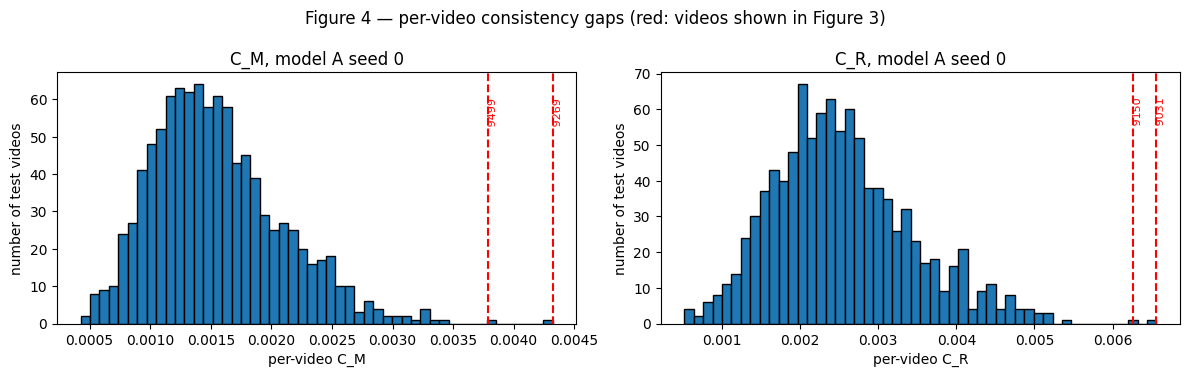

In [ ]:
# Table 3, Figure 3, Figure 4
cols = ['E5_1x', 'CM', 'EM', 'CR', 'ER']
labs = ['E⁽⁵⁾', 'C_M', 'E_M', 'C_R', 'E_R']
table3 = make_table([('A', RA, None), ('Blank', [R_BLANK], None), ('Copy-last', [R_COPY], None)], cols, labs)
TABLES['Table 3'] = table3
display(table3)

rA0 = RA[0]
top_M = list(np.argsort(-rA0['CM_pv'])[:2])
top_R = list(np.argsort(-rA0['CR_pv'])[:2])
FIG3_PICKS = [(int(p), 'M') for p in top_M] + [(int(p), 'R') for p in top_R]
print('Figure 3 videos:', [(TEST_IDX.start + p, t) for p, t in FIG3_PICKS])
FIG3_GIFS = consistency_figure(mA, FIG3_PICKS, 'figure3', 'model A seed 0')

fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
for a, tn, picks in ((ax[0], 'M', top_M), (ax[1], 'R', top_R)):
    v = rA0['C' + tn + '_pv']
    a.hist(v, bins=50, edgecolor='k')
    for p in picks:
        a.axvline(v[p], color='r', ls='--')
        a.text(v[p], a.get_ylim()[1] * 0.9, f' {TEST_IDX.start + p}', color='r', fontsize=8, rotation=90, va='top')
    a.set(xlabel=f'per-video C_{tn}', ylabel='number of test videos', title=f'C_{tn}, model A seed 0')
fig.suptitle('Figure 4 — per-video consistency gaps (red: videos shown in Figure 3)')
fig.tight_layout(); fig.savefig(f'{OUT}/figs/figure4.png', dpi=150); plt.show()

**Q2.6.** Blank and Copy-last are exactly consistent under mirror and rotation. What does this say
about reading CT on its own, and why does ET always have to be reported next to it?

**Answer:** Blank and Copy-last both have C_M=C_R=0, yet they perform worse than Model A, with errors of 0.0426 and 0.0641 compared with about 0.023. Their consistency comes from how they operate, not from learning motion: a blank frame remains blank under any transformation, while copying the last frame commutes with mirroring and rotation.

This shows that consistency does not necessarily mean accuracy. \(C_T\) measures whether a model behaves consistently under a transformation, not whether its predictions are correct. Even a useless predictor can achieve zero consistency error.

That is why we also need \(E_T\), which measures prediction accuracy on transformed inputs. A meaningful pass requires both low \(C_T\) and an \(E_T\) close to the original error E^(5). Model A meets this criterion: its mirror and rotation errors are 0.0228 and 0.024, only about 3% and 8% above its original error of 0.0222. Its consistency gaps are also small, at 0.00163 and 0.00288, respectively.

Figure 3 highlights another issue: blurry predictions can appear more consistent because two blurred outputs differ less than two sharp ones. Thus, low consistency error alone is not evidence of good generalisation; it must be considered alongside prediction accuracy.

**Q2.7.** Pick one video in Figure 3 where rows 3 and 4 disagree and describe precisely how the
model’s account of the motion changes. For example, a digit goes the wrong way, gets lost,
bounces too early or not at all, or blurs into something unrecognisable.

**Answer:** In video 9031, the 3 and 5 initially overlap but then separate horizontally. After a 90° rotation, they separate vertically: the 5 moves up while the rotated 3 moves down, leaving a widening gap in the ground truth R(Y).

The model’s original forecast f(X) is already blurry, and row 4, R(f(X)), simply rotates that forecast. The key difference between rows 3 and 4 is therefore not sharpness, but how the predicted motion unfolds.

Row 4, R(f(X)): Two distinct smudges move apart, roughly following the ground truth. The gap between them remains visible even at h=5, suggesting that the model’s original forecast preserves the idea of two objects moving apart.

Row 3, f(R(X)): At h=1, the two smudges are roughly in the correct positions. From h=2 onwards, they spread towards each other instead. By h=3, the gap has filled in, and by h=5, they have merged into a single vertical column.

The model therefore handles horizontal separation better than the same motion rotated vertically. Since vertical motion is common in training, the failure is more likely related to appearance than unfamiliar motion. The rotated digits, combined with their initial overlap, may make it harder for the model to distinguish their strokes, causing the same blurred merging seen in Figure 2. This likely explains why video 9031 has one of the largest C_R values in Figure 4.

**Q2.8.** Is rotation harder than mirroring for model A? Using your answers to Q2.1 and Q2.2, argue
whether the difference comes from the motion or from the digits’ appearance.

**Answer:** Yes rotation is harder for Model A than mirroring. Its consistency gap is almost twice as large C_R=0.00288 vs. C_M=0.00163, and the two seeds agree on this difference. Accuracy also drops more under rotation: E_R=0.024, about 8% above the original error, compared with E_M=0.0228, only 3% higher. Figure 4 confirms that this difference holds across the distributions, not just a few videos.

Motion is unlikely to explain the gap because both transformations preserve speed and produce directions already seen in training. The difference is more likely due to appearance. Mirroring keeps digits upright, reversing their handedness, while rotation changes their orientation entirely, turning vertical strokes horizontal and making familiar digits look less familiar. Since Model A was trained on upright digits and its convolutions are not rotation-invariant, it may struggle more with rotated digits, especially when they overlap, as in video 9031.

To check this further, we could compare rotation consistency across videos with different dominant motion directions. If the gap remains similar, that would support appearance rather than motion as the main cause.

,Model,E⁽²⁾ 1×,E⁽²⁾ 2×,E⁽²⁾ 3×,E⁽⁵⁾ 1×,E⁽⁵⁾ 2×
0,A,"0.0189 (0.0191, 0.0186)","0.0442 (0.0435, 0.0449)","0.0511 (0.0509, 0.0514)","0.0222 (0.0225, 0.022)","0.0484 (0.0476, 0.0493)"
1,Copy-last,0.0548,0.0661,0.0703,0.0641,0.0719


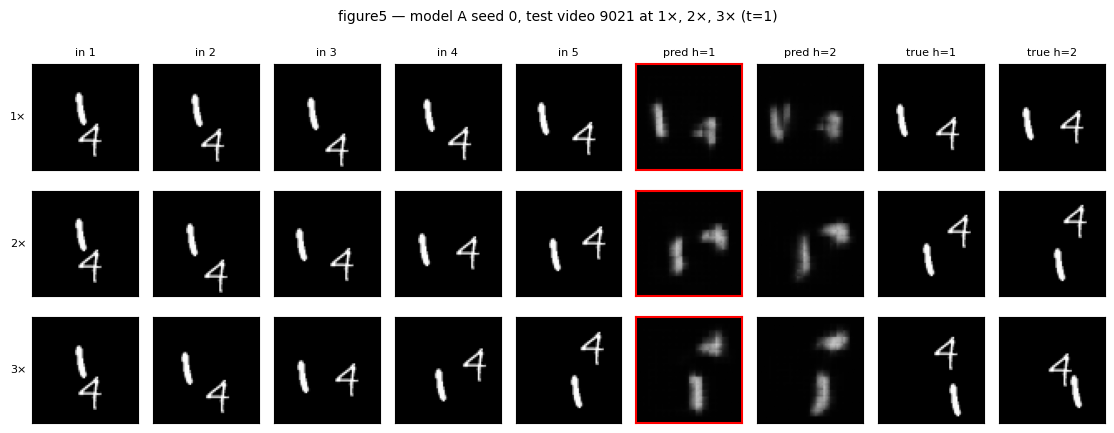

Figure 5 test video: 9021 — check visually that digits never overlap


In [ ]:
#Table 4 and Figure 5
cols = ['E2_1x', 'E2_2x', 'E2_3x', 'E5_1x', 'E5_2x']
labs = ['E⁽²⁾ 1×', 'E⁽²⁾ 2×', 'E⁽²⁾ 3×', 'E⁽⁵⁾ 1×', 'E⁽⁵⁾ 2×']
table4 = make_table([('A', RA, None), ('Copy-last', [R_COPY], None)], cols, labs)
TABLES['Table 4'] = table4
display(table4)

FIG5_POS = None
if FIG5_POS is None:
    for pos in range(len(X1)):
        shown = []
        for k in (1, 2, 3):
            Xk, Yk, _ = WIN_TEST[k]
            shown += list(Xk[pos]) + list(Yk[pos, :2])
        if no_overlap(shown):
            FIG5_POS = pos; break
speed_figure(mA, FIG5_POS, 'figure5', 'model A seed 0')
print('Figure 5 test video:', TEST_IDX.start + FIG5_POS, '— check visually that digits never overlap')

**Q2.9.** At what speed do model A’s predictions fall apart, and does this agree with the reach you
estimated in Q2.3? If not, what did your estimate miss? Describe what the failure in Figure 5
looks like (blur, a digit that stalls, a duplicated digit, a digit that vanishes) and what each
of these suggests the model is doing.

**Answer:** Model A’s performance drops sharply at 2×, earlier than the reach estimate in Q2.3 suggested. Its error rises from 0.0189 at 1× to 0.0442 at 2×, then increases slightly to 0.0511 at 3×. At both higher speeds, it performs worse than Blank (about 0.043), although it still beats Copy-last. Most of the damage therefore occurs between 1× and 2×.

This shows that architectural reach is not the same as learned capability. Although 6.6 px/frame at 2× is within the theoretical 8-pixel reach, the model was trained on speeds of roughly 2.8–4.3 px/frame. It learned to move digits at those typical speeds, not to estimate and handle much faster motion. At 3×, the additional problem is that movement exceeds the estimated reach. Errors also compound as the model feeds its own predictions back into subsequent steps.

Figure 5 illustrates this clearly. At 1×, the digits remain roughly in the correct positions. At 2×, the 4 lags behind and the 1 fades away. At 3×, the model misses the 4’s wall bounce and spreads the 1 into a long streak.

These failures suggest that the model has learned a typical speed rather than a general rule for tracking motion. Blurring reflects uncertainty about the digits’ positions, while fading indicates that the model increasingly defaults to weak predictions under MSE loss.

This motivates Model C: training on faster motion could improve performance at 2×. If 3× still fails, that would provide evidence that the architectural reach limit is also contributing.

**Q2.10.** From these results alone, can you tell whether the speed failure happens because fast motion
never appeared in training, or because it is beyond the model’s reach? Propose an experiment
that would tell the two apart.

**Answer:** The results do not fully separate the two explanations. At 3×, digits move about 10 px/frame, exceeding Model A’s 8-pixel reach, and the speed is also unfamiliar because training used only 1× motion.

The 2× result provides evidence that unfamiliar speed alone causes problems. At 6.6 px/frame, movement is within reach, yet \(E^{(2)}\) rises from 0.0189 at 1× to 0.0442 at 2×. However, the further increase to 0.0511 at 3× could reflect the reach limit, unfamiliar speed, or both.

Experiment: Compare four models, keeping training settings and evaluation consistent.

\begin{array}{c|c|c}
\textbf{Model} & \textbf{Architectural reach} & \textbf{Training speeds} \\
\hline
A & 8\text{ px} & 1\times \\
B & >10\text{ px} & 1\times \\
C & 8\text{ px} & 1\times\text{--}3\times \\
D & >10\text{ px} & 1\times\text{--}3\times
\end{array}


- Unfamiliar speed is the main problem: If C fixes both 2× and 3×, training on faster motion is sufficient.
- Reach also matters: If C fixes 2× but still fails at 3×, while D fixes 3×, the reach limit contributes to the failure.
- Both factors matter: If B still fails at higher speeds but C improves performance within reach, neither extra reach nor speed augmentation alone is sufficient.

A cheaper check is to group Model A’s 3× test videos by per-axis displacement. Diagonal movement may remain within the 8-pixel reach along each axis, while horizontal or vertical movement can exceed it. If errors rise sharply beyond 8 pixels per axis, that supports the reach-limit explanation. However, this is only suggestive because direction and speed may also affect difficulty.

**Q2.11.** Before training B–D, predict in at most three sentences which model will fix which of
the failures you found in Testing the Baseline. As with Q2.5, include this unedited in your
report.

**Answer:** Model B, trained with symmetry augmentation, should reduce C_M and C_R, especially the rotation gap, and bring E_M and E_R closer to E^(5). However, it should not fix the speed problem. Model C, trained on faster motion, should improve performance at 2× but only partly at 3× because the latter exceeds its 8-pixel reach. Its mirror and rotation gaps should remain similar to Model A’s. Model D, combining speed augmentation with greater reach, should perform best at both 2× and 3×, although its symmetry gaps may remain similar to Model A’s.

In [ ]:
D_CANDIDATES = {
    'D_dil13': dict(patch=4, hidden=64, kernels=(3, 3), dilations=(1, 3)),
    'D_dil12': dict(patch=4, hidden=64, kernels=(3, 3), dilations=(1, 2)),
    'D_patch8': dict(patch=8, hidden=64, kernels=(3, 3), dilations=(1, 1)),
}
reach_A = empirical_reach(CFG_A)[1]
for name, cfg in D_CANDIDATES.items():
    npar = n_params(ConvLSTMForecaster(**cfg))
    per_input, reach = empirical_reach(cfg)
    ok = npar <= 721_176 and reach > reach_A
    print(f'{name:9s} params {npar:,} (≤ 721,176: {npar <= 721_176}) | reach {reach} px vs A {reach_A} px | OK: {ok}')

CFG_D = D_CANDIDATES['D_dil13']         # <- your choice
assert n_params(ConvLSTMForecaster(**CFG_D)) <= 721_176 and empirical_reach(CFG_D)[1] > reach_A

D_dil13   params 480,784 (≤ 721,176: True) | reach 16 px vs A 8 px | OK: True
D_dil12   params 480,784 (≤ 721,176: True) | reach 12 px vs A 8 px | OK: True
D_patch8  params 594,496 (≤ 721,176: True) | reach 16 px vs A 8 px | OK: True


In [ ]:
# compare D candidates on the VALIDATION split only (short runs, seed 0)
RUN_D_SELECTION = False
VAL_EPOCHS = 8
if RUN_D_SELECTION:
    WIN_VAL = {k: make_windows(VAL_IDX, k) for k in (1, 2, 3)}
    rows = []
    for name, cfg in D_CANDIDATES.items():
        m, _ = train(f'val_{name}', cfg, 0, speed_aug=True, epochs=VAL_EPOCHS)
        r = evaluate(m, WIN_VAL)
        rows.append({'candidate': name, 'val E5 1×': fmt(r['E5_1x']), 'val E2 1×': fmt(r['E2_1x']),
                     'val E2 2×': fmt(r['E2_2x']), 'val E2 3×': fmt(r['E2_3x'])})
    display(pd.DataFrame(rows))

In [ ]:
#train B, C, D (two seeds each)
TRAIN_DB = False
SPECS = {'A': (CFG_A, False, False),
         'B': (CFG_A, False, True),       # 1x only, symmetry augmentation
         'C': (CFG_A, True, False),       # speed augmentation
         'D': (CFG_D, True, False)}       # larger reach + speed augmentation
if TRAIN_DB:
    SPECS['D+B'] = (CFG_D, True, True)
for name, (cfg, sa, ga) in SPECS.items():
    for s in (0, 1):
        if (name, s) not in MODELS:
            MODELS[(name, s)] = train(name.replace('+', 'p'), cfg, s, speed_aug=sa, sym_aug=ga)

[D s0] loaded finished checkpoint
[D s1] loaded finished checkpoint


In [ ]:
# Table 5
COLS5 = ['E5_1x', 'CM', 'EM', 'CR', 'ER', 'E2_1x', 'E2_2x', 'E2_3x', 'params', 'train', 'infer_time']
LABS5 = ['E⁽⁵⁾ 1×', 'C_M', 'E_M', 'C_R', 'E_R', 'E⁽²⁾ 1×', 'E⁽²⁾ 2×', 'E⁽²⁾ 3×', 'Params',
         'Train s/epoch', 'Inference s']

def model_row(name, label=None, sym=False):
    rs, tt = [], []
    for s in (0, 1):
        m, info = MODELS[(name, s)]
        f = Symmetrised(m) if sym else m
        r = dict(get_results(('sym_' if sym else '') + name.replace('+', 'p'), s, f))
        r['train'] = info['train_time_per_epoch']
        rs.append(r)
    extra = {'params': fmt(MODELS[(name, 0)][1]['params'])}
    return (label or name, rs, extra)

table5 = make_table([model_row(n) for n in SPECS], COLS5, LABS5)
TABLES['Table 5'] = table5
display(table5)
print('Hardware:', HARDWARE)

,Model,E⁽⁵⁾ 1×,C_M,E_M,C_R,E_R,E⁽²⁾ 1×,E⁽²⁾ 2×,E⁽²⁾ 3×,Params,Train s/epoch,Inference s
0,A,"0.0222 (0.0225, 0.022)","0.00163 (0.00155, 0.00171)","0.0228 (0.0231, 0.0226)","0.00288 (0.00254, 0.00321)","0.024 (0.024, 0.0239)","0.0189 (0.0191, 0.0186)","0.0442 (0.0435, 0.0449)","0.0511 (0.0509, 0.0514)","480,784","10.8 (10.9, 10.8)","0.48 (0.508, 0.453)"
1,B,"0.0229 (0.0236, 0.0222)","0.00122 (0.00117, 0.00128)","0.0228 (0.0235, 0.0221)","0.00157 (0.00148, 0.00166)","0.0228 (0.0234, 0.0221)","0.0194 (0.02, 0.0187)","0.0445 (0.0439, 0.045)","0.051 (0.0491, 0.0528)","480,784","11.4 (11.4, 11.4)","0.501 (0.52, 0.481)"
2,C,"0.0272 (0.0268, 0.0277)","9.89e-04 (0.00114, 8.42e-04)","0.0274 (0.027, 0.0278)","0.00219 (0.00245, 0.00193)","0.0283 (0.0279, 0.0287)","0.0236 (0.0236, 0.0236)","0.0289 (0.0287, 0.029)","0.0333 (0.0329, 0.0336)","480,784","10.7 (10.6, 10.7)","0.48 (0.481, 0.479)"
3,D,"0.0282 (0.0281, 0.0283)","6.24e-04 (6.98e-04, 5.51e-04)","0.0284 (0.0283, 0.0285)","0.00169 (0.00187, 0.00151)","0.0292 (0.0291, 0.0292)","0.0257 (0.0254, 0.0259)","0.0296 (0.0295, 0.0298)","0.0329 (0.033, 0.0327)","480,784","17.2 (17.3, 17.2)","0.753 (0.766, 0.74)"


Hardware: Tesla T4


**Q2.12** Describe model D and estimate its reach the same way you did in Q2.3, showing that it is
strictly larger than model A’s.

**Answer:**  Model D keeps Model A’s architecture but changes the second ConvLSTM layer’s 3×3 gate convolution to use dilation 3. Its kernel taps are three grid cells apart, with padding set to 3 to preserve the 16×16 grid. Everything else stays the same, including the 4×4 pixel folding, two ConvLSTM layers with 64 hidden channels, and the 1×1 output convolution followed by pixel_shuffle.

Dilation increases the model’s reach without adding parameters, so Model D still has 480,784 parameters, within the 721,176 budget. Like Model C, it is trained on 1×, 2× and 3× motion.

This addresses the limitation identified in Q2.9–Q2.10: at 3×, digits move about 10 px/frame, exceeding Model A’s 8-pixel reach. A 5×5 kernel would push the parameter count to roughly one million, exceeding the budget, while folding into 8×8 patches would reduce spatial detail. Dilation offers a longer reach without either drawback.

**Reach per time step**

Each grid cell still represents 4 original pixels. Layer 1 moves information by up to one cell, while the dilated second layer reaches up to three cells.

\begin{array}{c|c|c}
\text{Input path} & \text{Model A reach} & \text{Model D reach} \\
\hline
u_\tau \text{ or } h^{(1)}_{\tau-1} & 8 \text{ px} & 16 \text{ px} \\
h^{(2)}_{\tau-1} & 4 \text{ px} & 12 \text{ px} \\
c^{(1)}_{\tau-1} & 4 \text{ px} & 12 \text{ px} \\
c^{(2)}_{\tau-1} & 0 \text{ px} & 0 \text{ px}
\end{array}


Model D therefore reaches 16 px per time step along its longest paths, enough to cover the roughly 10 px/frame movement at 3×.

Although dilation skips intermediate cells within its own kernel, the first layer’s offsets combine with the second layer’s dilated offsets to cover a continuous range of positions along the main paths. The previous hidden state of layer 2 alone has a sparser reach, but information from the new input can still travel across intermediate positions.

The numerical empirical_reach(CFG_D) check confirms these results: 16 px for \(u_\tau\) and \(h^{(1)}_{\tau-1}\), and 12 px for \(h^{(2)}_{\tau-1}\).

**Q2.13.** Label each failure from Testing the Baseline as appearance, unfamiliar motion, or architectural
reach, citing the comparison in Table 5 that supports each label. In particular, if model C
still does badly at 3× while model D does well, what does that tell you, and why can’t more
training data carry information further than the architecture allows?

**Answer:**

**Mirror and rotation → appearance**

Models A and B have the same architecture, reach, and training speeds. The only difference is that B sees mirrored and rotated digits during training. This reduces \(C_R\) by 45% (0.00288 to 0.00157) and \(C_M\) by 25% (0.00163 to 0.00122). More importantly, B's transformed-scene errors match its original error: both \(E_M\) and \(E_R\) are 0.0228, close to \(E^{(5)}=0.0229\). Its speed performance remains unchanged. This supports Q2.8: the original failures came mainly from unfamiliar digit appearances, not motion. The remaining consistency gaps show that augmentation encourages symmetry but does not guarantee it.

Models C and D also have lower \(C_M\), but this does not necessarily mean better symmetry. Their higher errors (\(E^{(5)}=0.0272\) and \(0.0282\)) suggest blurrier predictions, which can reduce consistency gaps on their own. B is the only model that eliminates the extra error on transformed scenes.

**2× speed → unfamiliar motion**


Models A and C have the same architecture and 8 px reach, but C is trained on faster motion. Its 2× error drops from 0.0442 to 0.0289, a 35% reduction. Since 6.6 px per frame is within the model's reach, this improvement shows that unfamiliar speeds—not the reach limit—caused most of the original failure.
3× speed → mostly unfamiliar motion, not limited reach
At 3× speed, training augmentation alone reduces error from 0.0511 for A to 0.0333 for C. Model D increases the reach from 8 px to 16 px, but its error is 0.0329—effectively the same as C within seed variation. Thus, extra reach provides no measurable benefit. My Q2.11 prediction that only D would handle 3× motion was incorrect.

If C had performed poorly while D succeeded, that would have pointed to an architectural limitation. Both models see the same fast-motion examples, but C cannot use information beyond its receptive field within one step. Training can improve how existing connections are used, but it cannot extend the receptive field.
Why reach made little difference
The 8 px limit applies separately to each axis. Although 3× motion averages around 10 px per frame overall, diagonal movement often stays within 8 px per axis. Only fast, nearly horizontal or vertical movements are likely to exceed the limit. These cases may be too rare to noticeably affect average error, and recurrence can help carry information across steps.

C still performs worse at 3× than at 1× (0.033 versus 0.024), but increasing reach does not fix this. The remaining difficulty appears to come mainly from predicting unfamiliar, faster motion.

To test this further, we could group 3× test videos by their maximum per-axis displacement and compare C and D specifically on videos exceeding 8 px. This would reveal whether extra reach helps in the cases where the limit should matter most.

**Q2.14.** Did any of these changes cost accuracy on the original 1× clips? If so, was it worth it?

**Answer:** Yes for C and D, and only marginally for B:
* Model B (Negligible cost, clear win): The performance trade-off for Model B is minimal. On $E^{(5)}$, B’s seed variation ranges from $0.0222$ to $0.0236$, which heavily overlaps with Model A’s range of $0.0220$ to $0.0225$. The $\sim 3\%$ difference is essentially within the margin of seed noise. A slight overhead is expected given that only an eighth of B’s training samples feature upright digits, forcing the same parameters to generalize across mirrored and rotated variations. In return, B halves $C_R$ and completely eliminates the performance penalty on transformed scenes—making it a substantial gain for almost no loss.
* Model C (Noticeable $1\times$ cost, highly worth it for multi-speed robust setups): Model C introduces a genuine performance trade-off, but it is well worth the cost if playback speeds vary. At $1\times$, C performs about $25\%$ worse. Because training speeds are split evenly across $1\times$, $2\times$, and $3\times$, only a third of the training windows are presented at baseline speed, forcing its 480,784 parameters to cover all three regimes (resulting in visibly blurrier $1\times$ forecasts). However, its error at $2\times$ and $3\times$ drops by roughly $35\%$. Across all three speeds, average $E^{(2)}$ drops from $0.0381$ (Model A) to $0.0286$ (Model C). While Model A performs worse than the baseline Blank predictor at elevated speeds ($0.0442$ at $2\times$ and $0.0511$ at $3\times$ vs. $\sim 0.043$), Model C outperforms the Blank predictor across the board. If the system only encounters standard-speed video, Model A remains the better pick; if speed variability is expected, trading away some $1\times$ precision for high-speed reliability is a clear win.
* Model D (Inferior trade-off to C): Model D fails to justify its added overhead compared to C. It suffers a higher $1\times$ error than C ($E^{(2)}$ of $0.0257$ vs. $0.0236$, roughly $9\%$ worse) without offering meaningful gains at higher speeds ($0.0296$ vs. $0.0289$ at $2\times$, and $0.0329$ vs. $0.0333$ at $3\times$, both well within seed variance). This $1\times$ degradation is likely driven by the dilation itself: Layer 2’s taps are spaced 3 cells apart, missing fine local detail and leaving spatial gaps in the $h^{(2)}$ memory path that impair tracking of fine, short-range motion. Model D is also computationally heavier, taking $17.2\text{ s}$ per epoch vs. $11.3\text{ s}$ for C during training, and $0.75\text{ s}$ vs. $0.48\text{ s}$ during test inference. Given that reach capacity was not the primary bottleneck at $3\times$ (as established in Q2.13), the extra receptive field does not justify the runtime overhead.

Training Duration Note: Because all models were capped at 30 epochs, part of the $1\times$ performance drop in C and D likely stems from seeing only a third as many $1\times$ training windows. Extended training might narrow this gap, though these experiments do not explicitly test for it.

## 5. The final model — symmetrised forecasters

,Model,E⁽⁵⁾ 1×,C_M,E_M,C_R,E_R,E⁽²⁾ 1×,E⁽²⁾ 2×,E⁽²⁾ 3×,Params,Train s/epoch,Inference s
0,Sym(B),"0.0222 (0.0229, 0.0215)","8.76e-17 (8.41e-17, 9.10e-17)","0.0222 (0.0229, 0.0215)","7.10e-17 (6.85e-17, 7.35e-17)","0.0222 (0.0229, 0.0215)","0.0189 (0.0195, 0.0183)","0.0436 (0.043, 0.0441)","0.0497 (0.0478, 0.0516)","480,784","11.4 (11.4, 11.4)","3.88 (3.87, 3.9)"
1,Sym(D),"0.0282 (0.028, 0.0283)","4.68e-17 (4.63e-17, 4.72e-17)","0.0282 (0.028, 0.0283)","3.52e-17 (3.34e-17, 3.70e-17)","0.0282 (0.028, 0.0283)","0.0256 (0.0254, 0.0259)","0.0296 (0.0295, 0.0297)","0.0328 (0.0329, 0.0326)","480,784","17.2 (17.3, 17.2)","5.91 (5.9, 5.92)"


Sym(B): C_M per seed = 8.41e-17, 9.10e-17 | C_R per seed = 6.85e-17, 7.35e-17  (should be ~0)
Sym(D): C_M per seed = 4.63e-17, 4.72e-17 | C_R per seed = 3.34e-17, 3.70e-17  (should be ~0)


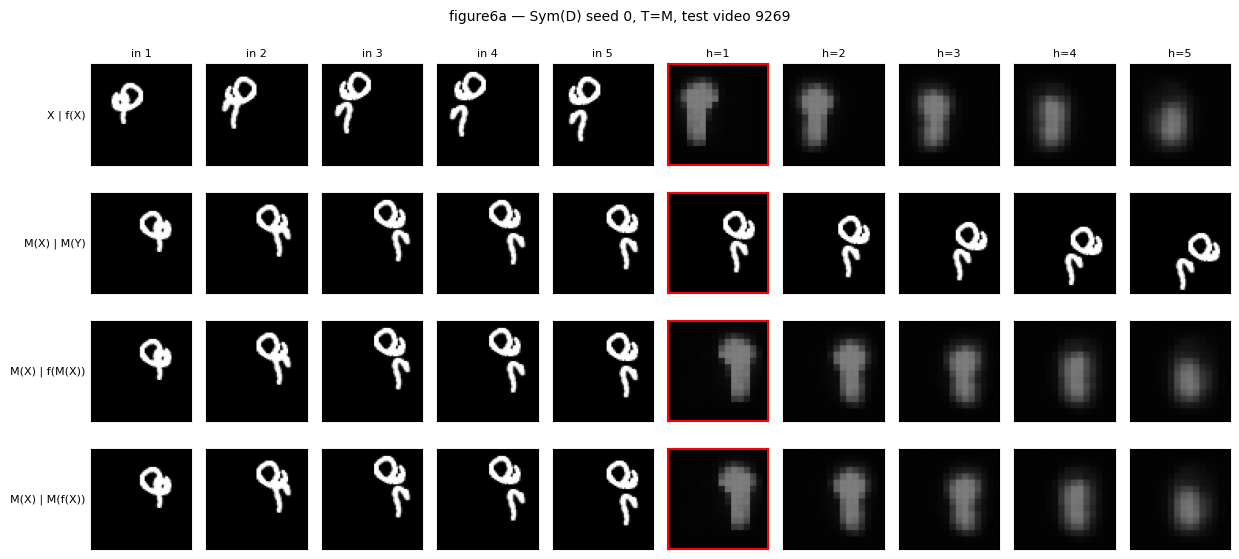

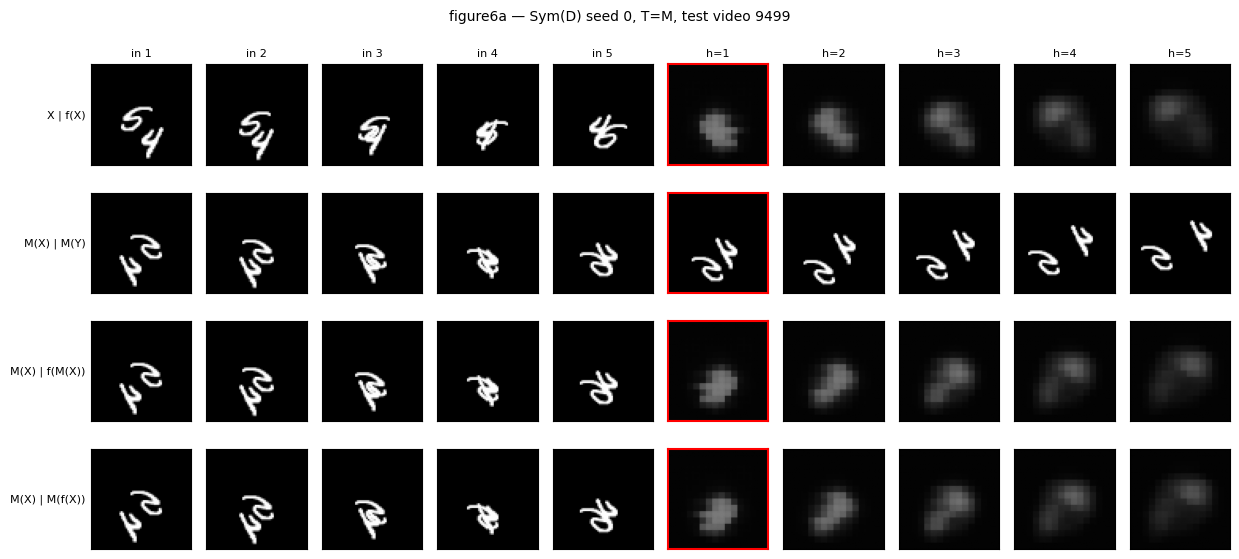

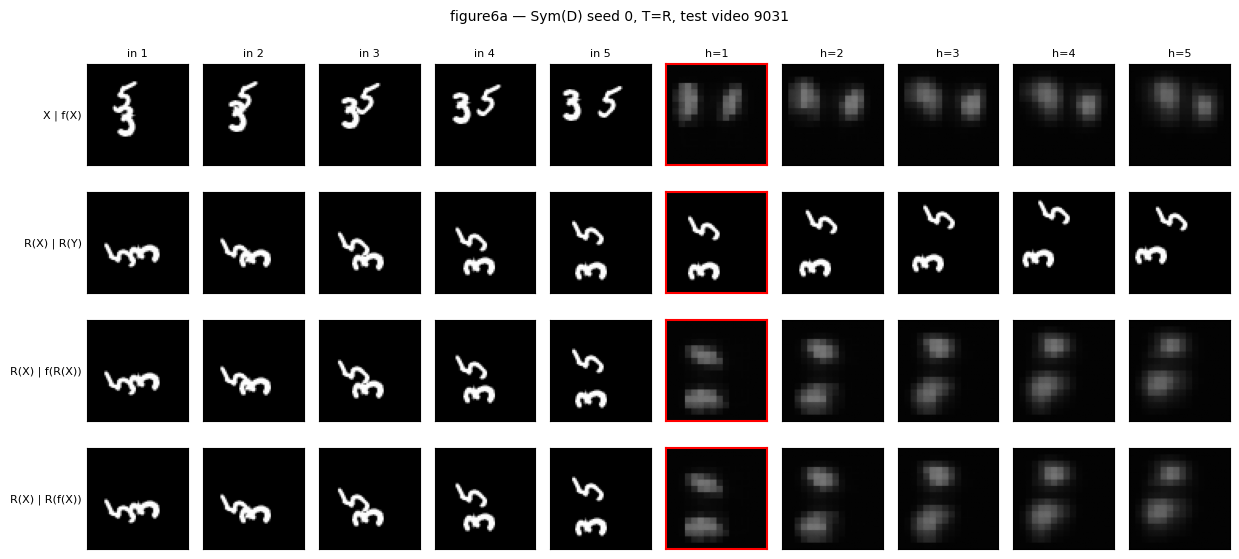

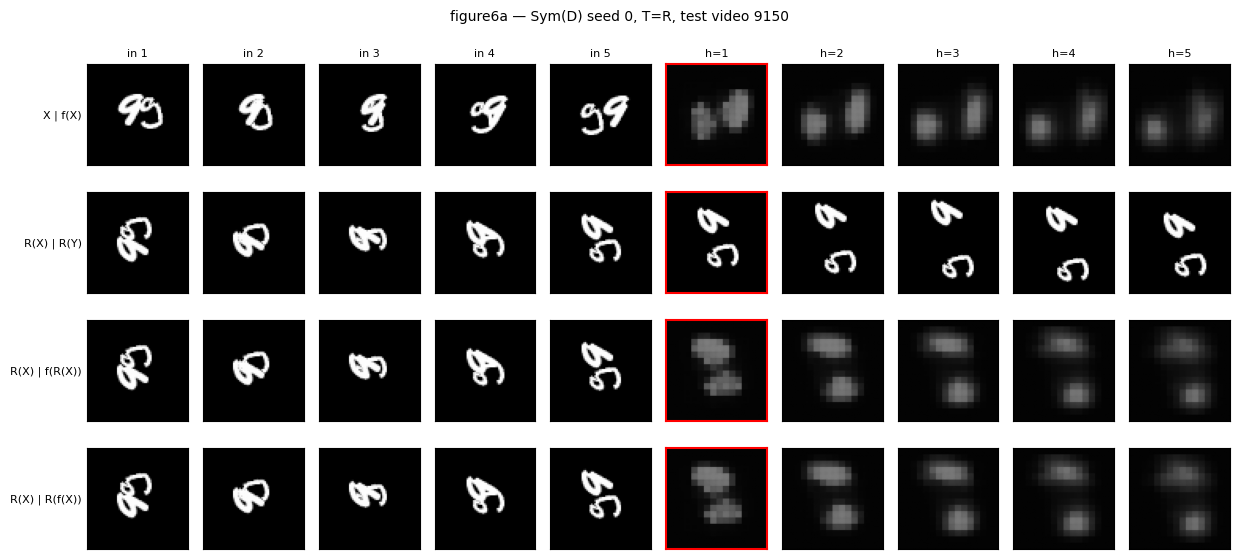

GIFs:
  /content/drive/MyDrive/AI651_A2_Q2/gifs/figure6a_M_video9269.gif
  /content/drive/MyDrive/AI651_A2_Q2/gifs/figure6a_M_video9499.gif
  /content/drive/MyDrive/AI651_A2_Q2/gifs/figure6a_R_video9031.gif
  /content/drive/MyDrive/AI651_A2_Q2/gifs/figure6a_R_video9150.gif


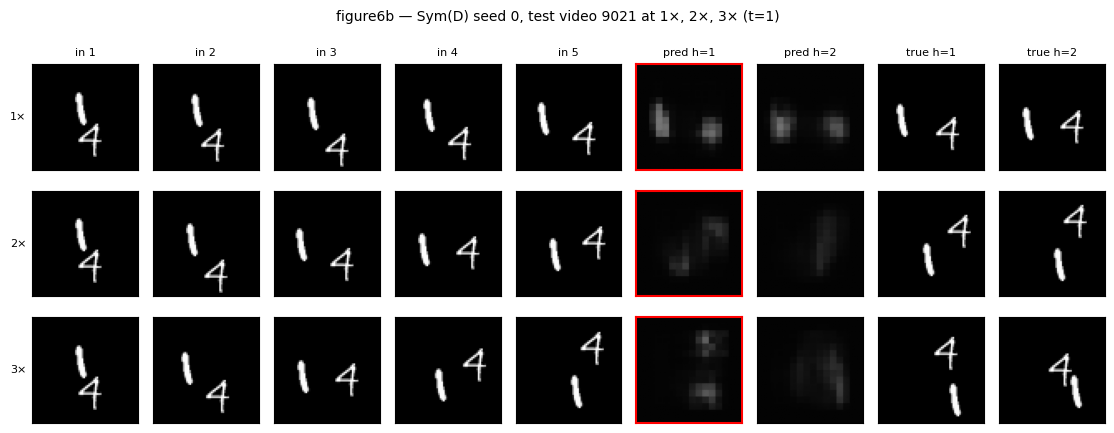

In [ ]:
#Table 6 and Figure 6
FINAL = 'D+B' if TRAIN_DB else 'D'
rows6 = [model_row('B', 'Sym(B)', sym=True), model_row('D', 'Sym(D)', sym=True)]
if FINAL == 'D+B':
    rows6.append(model_row('D+B', 'Sym(D+B)', sym=True))
table6 = make_table(rows6, COLS5, LABS5)
TABLES['Table 6'] = table6
display(table6)
for label, rs, _ in rows6:
    cm = ', '.join(f"{r['CM']:.2e}" for r in rs)
    cr = ', '.join(f"{r['CR']:.2e}" for r in rs)
    print(f'{label}: C_M per seed = {cm} | C_R per seed = {cr}  (should be ~0)')

final0 = Symmetrised(MODELS[(FINAL, 0)][0])
FIG6_GIFS = consistency_figure(final0, FIG3_PICKS, 'figure6a', f'Sym({FINAL}) seed 0')
speed_figure(final0, FIG5_POS, 'figure6b', f'Sym({FINAL}) seed 0')

**Q2.15.** Compare symmetry that is learned (model B) with symmetry that is built in (the symmetrised
models) in terms of consistency, accuracy on original and transformed clips, and inference
cost. Which one is exact, and why? Averaging eight predictions can also blur them; when
would you expect built-in symmetry to hurt accuracy, and did it here?

**Answer:** While data augmentation encourages approximate symmetry, Model B still exhibits small errors ($C_M, C_R \approx 10^{-3}$). In contrast, hard-coding symmetry achieves exact invariance down to machine precision ($C_M, C_R \approx 10^{-17}$). This exactness is guaranteed algebraically for any model $f$. By constructing an equivariant forecaster over all eight group transformations $g \in D_4$ via $\bar{f}(X) = \frac{1}{8} \sum_{g} g^{-1} f(g X)$, applying a transformation $T$ simply reorders the summation terms, proving that $\bar{f}(TX) = T\bar{f}(X)$ holds identically. Data augmentation alone can only approximate this relationship during training.

Because spatial transformations merely permute pixel coordinates without altering Mean Squared Error (MSE), exact equivariance guarantees that transformed loss matches baseline loss ($E_T = E^{(5)}$). For Model B, symmetrization lowers baseline error ($E^{(5)}$ drops from $0.0229$ to $0.0222$), matching Model A while slightly improving multi-speed forecasts. For Model D, the primary gain appears on transformed inputs, where rotation error $E_R$ drops from $0.0292$ to $0.0282$ without degrading baseline accuracy. Built-in symmetry does not hurt performance in either case.

The primary trade-off lies in computational overhead. Symmetrization requires zero extra training time, but it increases test-time inference cost by roughly $7.8\times$ because every prediction requires eight forward passes plus transformations and averaging. For 1,000 test videos, inference time grows from $0.50\text{ s}$ to $3.88\text{ s}$ for Model B and from $0.75\text{ s}$ to $5.91\text{ s}$ for Model D. Learned symmetry costs nothing extra at inference, whereas built-in symmetry scales compute directly with the size of the symmetry group.

Under MSE loss, ensembling eight transformed passes cannot increase error unless the base model severely degrades on rotated inputs (like Model A) or the task breaks spatial symmetry (such as distinguishing 6 from 9). Neither condition applies here. Moving MNIST dynamics are isotropic, and because Models B and D are already near-consistent, ensembling acts as a beneficial 8-member blend that reduces variance. Any visual blurring observed in Model D stems from its underlying architecture rather than the averaging process itself. Ultimately, hard-coded symmetry provides exact mathematical guarantees and equal or superior accuracy over data augmentation, at the cost of an $8\times$ inference penalty.

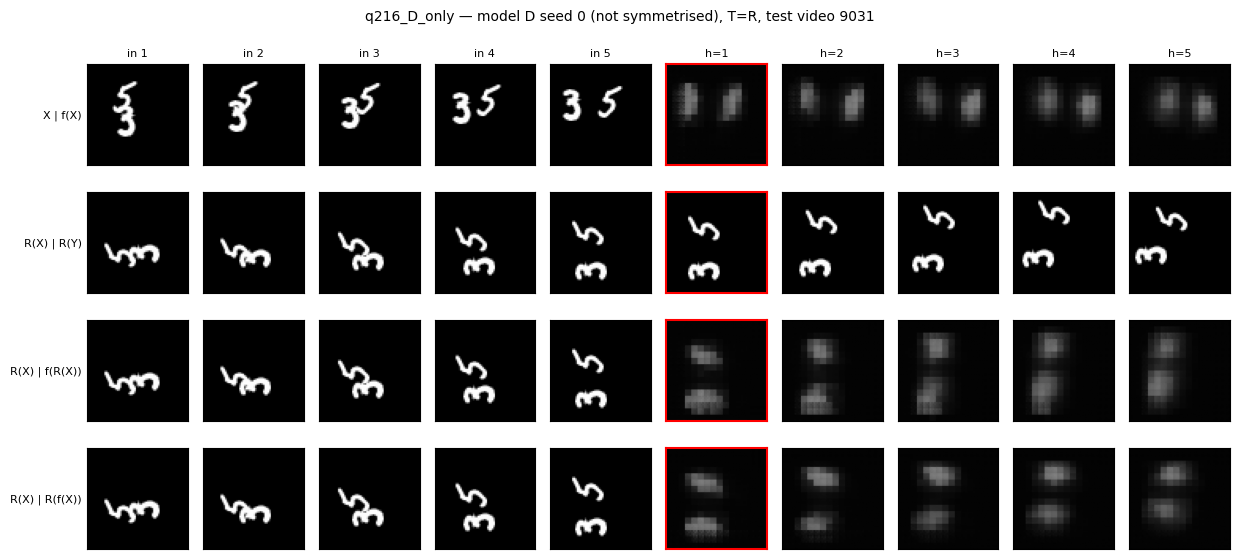

GIFs:
  /content/drive/MyDrive/AI651_A2_Q2/gifs/q216_D_only_R_video9031.gif


['/content/drive/MyDrive/AI651_A2_Q2/gifs/q216_D_only_R_video9031.gif']

In [ ]:
consistency_figure(MODELS[('D', 0)][0], [(31, 'R')], 'q216_D_only', 'model D seed 0 (not symmetrised)')

**Q2.16.** Go back to the video you discussed in Q2.7. Does the final model now get it right (Figure 6),
and which change fixed which part of the failure?


**Answer:**  Mostly yes. The final model gets the motion right, but not the digits’ appearance. In Figure 6, rows 3 and 4 are identical, and both show the correct motion: two separate horizontal blobs, the upper one (the 5) moving up and the lower one (the 3) moving down and to the left, with a clear dark gap between them all the way to h = 5. Their positions roughly follow the ground truth R(Y), with the upper blob slightly behind the true 5 at later horizons. The failure from Q2.7 is gone: the digits no longer stretch towards each other and merge into a single column. What’s still wrong is the shape. Both digits are shapeless smudges from h = 1 and fade over the horizons, so neither the 5 nor the 3 can be recognised.

To find which change fixed what, I ran the plain model D, without symmetrisation, on the same video. It still fails the way model A did. Rotated back, its forecast for the original scene (row 4) keeps two separate blobs, but its forecast for the rotated scene (row 3) stretches the upper blob downwards from h = 2, and by h = 3 the two have merged into one vertical column. So D’s own changes, speed augmentation and a 16 px reach, did not fix this failure. That’s expected: the video is at 1×, its motion was already within model A’s reach, and Q2.13 found that rotation failures come from appearance, not motion.

The merge was fixed by built-in symmetry. Sym(D) averages D’s forecasts over all eight orientations, so its forecasts for the original and rotated scenes are identical. That alone would only make the forecasts match, not make them right. They come out right because most of the eight orientations, including the original one, give two separate blobs, and averaging keeps that shared answer while washing out the one orientation where D merges them. The blur was fixed by nothing. It comes from training with MSE, which rewards hedging between uncertain outcomes, and from the model feeding back its own blurred predictions. None of the changes targets either cause, so the digits’ shapes are still lost.

**Q2.17.** Final verdict (150 words max). Did your final model learn motion? What evidence would
convince a skeptic, and what is one test it still has not passed?

**Answer:** Partly. Sym(D) learned where digits go, but not what they look like. Its errors stay well below both baselines at every speed: E⁽²⁾ is 0.0256, 0.0296 and 0.0328 at 1×, 2× and 3×, against about 0.043 for Blank and 0.055–0.070 for Copy-last. So it predicts real movement rather than copying the last frame or fading to black. Its forecasts are exactly consistent under mirroring and rotation, with E_M = E_R = E⁽⁵⁾, and on video 9031 it keeps the two digits moving apart in the correct directions. To convince a skeptic that it learned motion rather than memorising digits, I would test it on shapes it never saw, such as moving letters or squares, and check that it still beats Copy-last. The test it still fails is keeping each digit’s shape. By h = 1 every digit is a shapeless blob, so a digit classifier would fail on its forecasts, and after digits overlap (video 9000) it cannot separate them again.